## 0. Setup

In [1]:
import sys, os, time
import numpy as np
sys.path.insert(0, os.path.abspath('.'))
import advantage_search as A          # structured generator + complete-QUBO builders + SA + search
try:
    import matplotlib.pyplot as plt; HAVE_PLT = True
except Exception:
    HAVE_PLT = False

# ---- evaluation budget --------------------------------------------------------------------
# A *moderate* SA budget on purpose: at a huge budget every QUBO eventually solves (no gap),
# at a tiny one none do; in between, FerQ-Bc's smaller search space separates it. TTS99 (also
# reported) is budget-independent and favours FerQ-Bc regardless.
N_INST, READS, SWEEPS = 100, 20, 900        # <-- running locally: raise N_INST (e.g. 50) for tighter stats

# ---- 2-D specification sweep: monomial degree  x  sub-aggregate sharing depth --------------
# Cost note: ground truth is brute-forced over 2^N per instance, and the high-degree/high-attach
# corner also runs a large Rosenberg QUBO. Expect a few-to-tens of minutes; to speed up, drop
# degree 11, shrink ATTACHES, or lower N_INST.
DEGREES  = [5, 7, 9, 11]                    # add higher degrees for a wider map (raises N -> 2^N ground truth)
ATTACHES = [1, 2, 4, 6, 8]                  # monomials sharing ONE core (sharing depth); 1 = no sharing
N_CORES, N_PAIR, SLACK = 1, 6, 1           # single shared core + a few random pairwise terms
def N_for(deg, attach):                    # keep #original vars minimal so 2^N brute-force stays cheap
    return (deg - 1) + attach + SLACK

n_settings = len(DEGREES) * len(ATTACHES)
maxN = max(N_for(d, a) for d in DEGREES for a in ATTACHES)
print("methods:", A.METHODS, "| budget %dx%d on %d instances" % (READS, SWEEPS, N_INST))
print("2-D sweep: %d degrees x %d sharing-depths = %d settings (max N=%d -> 2^%d ground truth)"
      % (len(DEGREES), len(ATTACHES), n_settings, maxN, maxN))
print("est. cost ~ %d settings x %d instances x 4 methods of SA; trim DEGREES/ATTACHES/N_INST to go faster."
      % (n_settings, N_INST))

methods: ['FerQ-Bc', 'Rosenberg', 'dimod', 'raw'] | budget 20x900 on 100 instances
2-D sweep: 4 degrees x 5 sharing-depths = 20 settings (max N=19 -> 2^19 ground truth)
est. cost ~ 20 settings x 100 instances x 4 methods of SA; trim DEGREES/ATTACHES/N_INST to go faster.


## 1. Search — 2-D sweep over degree x sub-aggregate sharing

For every (degree $d$, sharing depth `attach`) we build a structured HOBO (one core of size
$d\!-\!1$ carrying `attach` monomials) and record FerQ-Bc's **advantage**
$=\text{optrate}(\text{FerQ-Bc})-\max(\text{optrate}(\text{Rosenberg}),\text{optrate}(\text{dimod}))$.
The advantage should light up in the **high-degree, high-sharing** corner, where FerQ-Bc's
auxiliary count ($\nu(d\!-\!1)$, constant in `attach`) is far below per-term substitution
($\sim \texttt{attach}\cdot(d\!-\!2)$).

In [2]:
grid = [(N_for(d, a), d, N_CORES, a, N_PAIR) for d in DEGREES for a in ATTACHES]
t0 = time.time()
ranked = A.search(grid, n_inst=N_INST, reads=READS, sweeps=SWEEPS)
res_by_setting = {tuple(st): res for (st, adv, res) in ranked}
print("\nsweep done in %.0fs" % (time.time() - t0))

# advantage matrix  (rows = ATTACHES, cols = DEGREES)
ADV  = np.array([[res_by_setting[(N_for(d, a), d, N_CORES, a, N_PAIR)]["_adv_optrate"]
                  for d in DEGREES] for a in ATTACHES])
NAUX = np.array([[res_by_setting[(N_for(d, a), d, N_CORES, a, N_PAIR)]["FerQ-Bc"]["naux"]
                  for d in DEGREES] for a in ATTACHES])

DEMO_SETTING = ranked[0][0]                       # the max-advantage setting found
demo_res = res_by_setting[DEMO_SETTING]
print("-> best (max-advantage) setting:", DEMO_SETTING, " adv = %+.2f optrate" % ranked[0][1])

setting (6, 5, 1, 1, 6)       FerQ-Bc opt=1.00 aux= 4.0  |  best-deployable opt=1.00  |  adv=+0.00
setting (7, 5, 1, 2, 6)       FerQ-Bc opt=1.00 aux= 4.0  |  best-deployable opt=1.00  |  adv=+0.00
setting (9, 5, 1, 4, 6)       FerQ-Bc opt=1.00 aux= 4.0  |  best-deployable opt=1.00  |  adv=+0.00
setting (11, 5, 1, 6, 6)      FerQ-Bc opt=0.91 aux= 4.0  |  best-deployable opt=0.99  |  adv=-0.08
setting (13, 5, 1, 8, 6)      FerQ-Bc opt=0.87 aux= 4.0  |  best-deployable opt=0.99  |  adv=-0.12
setting (8, 7, 1, 1, 6)       FerQ-Bc opt=1.00 aux= 5.0  |  best-deployable opt=1.00  |  adv=+0.00
setting (9, 7, 1, 2, 6)       FerQ-Bc opt=0.98 aux= 5.0  |  best-deployable opt=0.99  |  adv=-0.01
setting (11, 7, 1, 4, 6)      FerQ-Bc opt=0.91 aux= 5.0  |  best-deployable opt=0.96  |  adv=-0.05
setting (13, 7, 1, 6, 6)      FerQ-Bc opt=0.82 aux= 5.0  |  best-deployable opt=0.91  |  adv=-0.09
setting (15, 7, 1, 8, 6)      FerQ-Bc opt=0.81 aux= 5.0  |  best-deployable opt=0.89  |  adv=-0.08
setting (1

## 2. Advantage heatmap over the specification grid

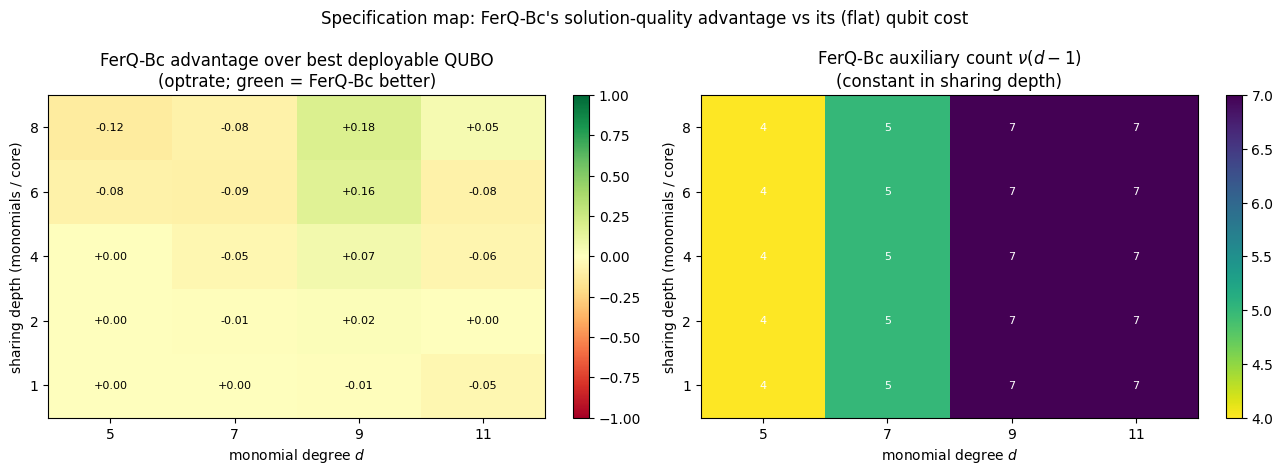

advantage matrix (rows=sharing depth [1, 2, 4, 6, 8], cols=degree [5, 7, 9, 11]):
  attach=1  : +0.00  +0.00  -0.01  -0.05
  attach=2  : +0.00  -0.01  +0.02  +0.00
  attach=4  : +0.00  -0.05  +0.07  -0.06
  attach=6  : -0.08  -0.09  +0.16  -0.08
  attach=8  : -0.12  -0.08  +0.18  +0.05


In [3]:
if HAVE_PLT:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    im0 = ax[0].imshow(ADV, origin="lower", aspect="auto", cmap="RdYlGn", vmin=-1, vmax=1,
                       extent=[min(DEGREES)-1, max(DEGREES)+1, -0.5, len(ATTACHES)-0.5])
    ax[0].set_yticks(range(len(ATTACHES))); ax[0].set_yticklabels(ATTACHES)
    ax[0].set_xticks(DEGREES); ax[0].set_xlabel("monomial degree $d$")
    ax[0].set_ylabel("sharing depth (monomials / core)")
    ax[0].set_title("FerQ-Bc advantage over best deployable QUBO\n(optrate; green = FerQ-Bc better)")
    for i in range(len(ATTACHES)):
        for j in range(len(DEGREES)):
            ax[0].text(DEGREES[j], i, "%+.2f" % ADV[i, j], ha="center", va="center", fontsize=8)
    plt.colorbar(im0, ax=ax[0], fraction=0.046)
    im1 = ax[1].imshow(NAUX, origin="lower", aspect="auto", cmap="viridis_r",
                       extent=[min(DEGREES)-1, max(DEGREES)+1, -0.5, len(ATTACHES)-0.5])
    ax[1].set_yticks(range(len(ATTACHES))); ax[1].set_yticklabels(ATTACHES)
    ax[1].set_xticks(DEGREES); ax[1].set_xlabel("monomial degree $d$")
    ax[1].set_ylabel("sharing depth (monomials / core)")
    ax[1].set_title("FerQ-Bc auxiliary count $\\nu(d-1)$\n(constant in sharing depth)")
    for i in range(len(ATTACHES)):
        for j in range(len(DEGREES)):
            ax[1].text(DEGREES[j], i, "%.0f" % NAUX[i, j], ha="center", va="center", fontsize=8, color="w")
    plt.colorbar(im1, ax=ax[1], fraction=0.046)
    fig.suptitle("Specification map: FerQ-Bc's solution-quality advantage vs its (flat) qubit cost", fontsize=12)
    fig.tight_layout(); plt.show()

# text summary of the sweep
print("advantage matrix (rows=sharing depth %s, cols=degree %s):" % (ATTACHES, DEGREES))
for i, a in enumerate(ATTACHES):
    print("  attach=%-2d : %s" % (a, "  ".join("%+.2f" % ADV[i, j] for j in range(len(DEGREES)))))

## 3. The winning regime — FerQ-Bc vs. the deployable QUBOs (and the raw ceiling)

Head-to-head at the max-advantage setting, plus an **unstructured control**: same $N$, degree and
number of high-order terms, but independent random supports (no shared sub-aggregate). If the
advantage is structural, it should vanish in the control.

In [4]:
control_res = A.run_setting(DEMO_SETTING, N_INST, READS, SWEEPS, structured=False)

def show(res, title):
    print(title)
    print("  %-10s %9s %12s %8s" % ("method", "optrate", "medTTS99", "n_aux"))
    for m in A.METHODS:
        r = res[m]
        tt = "inf" if not np.isfinite(r["medtts"]) else "%.0f" % r["medtts"]
        print("  %-10s %9.2f %12s %8.1f" % (m, r["optrate"], tt, r["naux"]))

show(demo_res,    "STRUCTURED (shared core)   setting=%s" % (DEMO_SETTING,))
print()
show(control_res, "UNSTRUCTURED control       (same N/degree/#terms, random supports)")

fq, ro, di, rw = (demo_res[m] for m in ("FerQ-Bc", "Rosenberg", "dimod", "raw"))
print("\nStructured verdict:")
print("  FerQ-Bc matches the raw ceiling: optrate %.2f vs raw %.2f — the only deployable QUBO that does."
      % (fq["optrate"], rw["optrate"]))
print("  vs Rosenberg : optrate %+.2f,  TTS x%.1f lower,  aux %.0f vs %.0f"
      % (fq["optrate"]-ro["optrate"], ro["medtts"]/max(fq["medtts"],1), fq["naux"], ro["naux"]))
print("  vs dimod     : optrate %+.2f,  TTS x%.1f lower,  aux %.0f vs %.0f"
      % (fq["optrate"]-di["optrate"], di["medtts"]/max(fq["medtts"],1), fq["naux"], di["naux"]))
print("  Remove the shared core -> FerQ-Bc aux %.0f -> %.0f and optrate %.2f -> %.2f: the win is STRUCTURAL."
      % (fq["naux"], control_res["FerQ-Bc"]["naux"], fq["optrate"], control_res["FerQ-Bc"]["optrate"]))

STRUCTURED (shared core)   setting=(17, 9, 1, 8, 6)
  method       optrate     medTTS99    n_aux
  FerQ-Bc         0.98        11700      7.0
  Rosenberg       0.35        18900     56.0
  dimod           0.80        39600      7.0
  raw             0.88         4050      0.0

UNSTRUCTURED control       (same N/degree/#terms, random supports)
  method       optrate     medTTS99    n_aux
  FerQ-Bc         0.21        81000     55.7
  Rosenberg       0.27        39600     56.0
  dimod           0.15        81000     29.1
  raw             1.00         4950      0.0

Structured verdict:
  FerQ-Bc matches the raw ceiling: optrate 0.98 vs raw 0.88 — the only deployable QUBO that does.
  vs Rosenberg : optrate +0.63,  TTS x1.6 lower,  aux 7 vs 56
  vs dimod     : optrate +0.18,  TTS x3.4 lower,  aux 7 vs 7
  Remove the shared core -> FerQ-Bc aux 7 -> 56 and optrate 0.98 -> 0.21: the win is STRUCTURAL.


## 4. Head-to-head plots at the winning setting

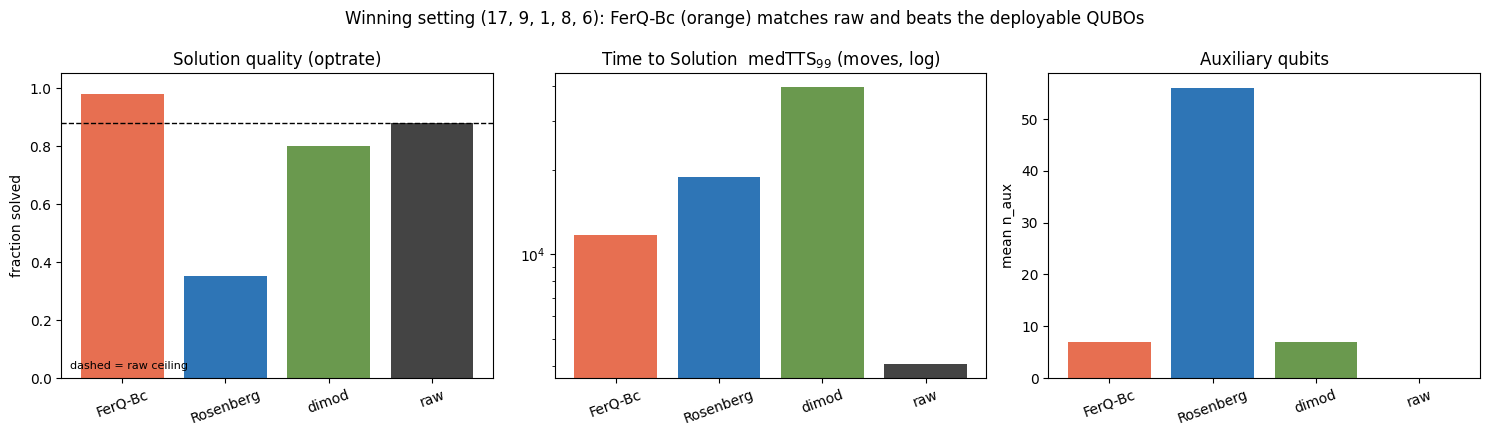

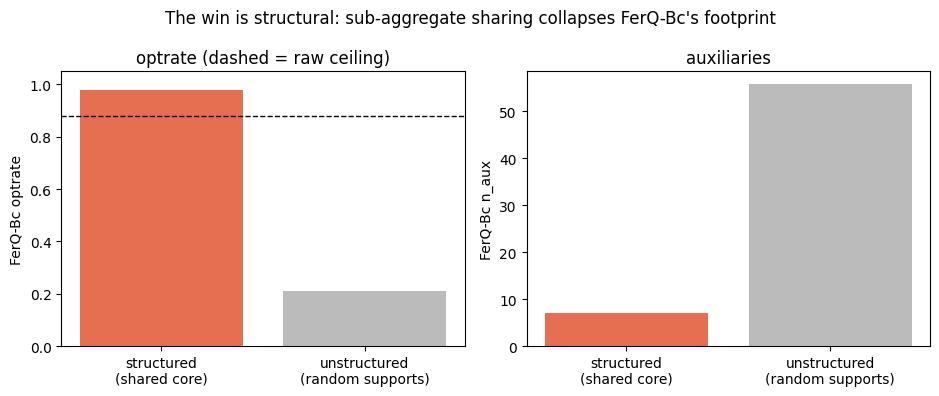

In [5]:
if HAVE_PLT:
    order = ["FerQ-Bc", "Rosenberg", "dimod", "raw"]
    col = ["#E76F51", "#2E75B6", "#6A994E", "#444444"]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
    x = np.arange(len(order))
    ax[0].bar(x, [demo_res[m]["optrate"] for m in order], color=col)
    ax[0].axhline(demo_res["raw"]["optrate"], ls="--", color="k", lw=1)
    ax[0].set_title("Solution quality (optrate)"); ax[0].set_ylim(0, 1.05); ax[0].set_ylabel("fraction solved")
    ax[0].set_xticks(x); ax[0].set_xticklabels(order, rotation=20)
    ax[0].text(0.02, 0.03, "dashed = raw ceiling", transform=ax[0].transAxes, fontsize=8)
    tts = [demo_res[m]["medtts"] for m in order]
    ax[1].bar(x, [t if np.isfinite(t) else 0 for t in tts], color=col)
    ax[1].set_yscale("log"); ax[1].set_title("Time to Solution  medTTS$_{99}$ (moves, log)")
    ax[1].set_xticks(x); ax[1].set_xticklabels(order, rotation=20)
    ax[2].bar(x, [demo_res[m]["naux"] for m in order], color=col)
    ax[2].set_title("Auxiliary qubits"); ax[2].set_ylabel("mean n_aux")
    ax[2].set_xticks(x); ax[2].set_xticklabels(order, rotation=20)
    fig.suptitle("Winning setting %s: FerQ-Bc (orange) matches raw and beats the deployable QUBOs"
                 % (DEMO_SETTING,), fontsize=12)
    fig.tight_layout(); plt.show()

    # structural contrast for FerQ-Bc (structured vs unstructured)
    fig2, ax2 = plt.subplots(1, 2, figsize=(9.5, 4))
    labels = ["structured\n(shared core)", "unstructured\n(random supports)"]
    ax2[0].bar(labels, [demo_res["FerQ-Bc"]["optrate"], control_res["FerQ-Bc"]["optrate"]],
               color=["#E76F51", "#BBBBBB"])
    ax2[0].axhline(demo_res["raw"]["optrate"], ls="--", color="k", lw=1)
    ax2[0].set_ylim(0, 1.05); ax2[0].set_ylabel("FerQ-Bc optrate"); ax2[0].set_title("optrate (dashed = raw ceiling)")
    ax2[1].bar(labels, [demo_res["FerQ-Bc"]["naux"], control_res["FerQ-Bc"]["naux"]],
               color=["#E76F51", "#BBBBBB"])
    ax2[1].set_ylabel("FerQ-Bc n_aux"); ax2[1].set_title("auxiliaries")
    fig2.suptitle("The win is structural: sub-aggregate sharing collapses FerQ-Bc's footprint")
    fig2.tight_layout(); plt.show()

## 5. Statistics of the metrics  (winning setting vs. unstructured control)

Beyond point estimates, the per-instance distributions. For each method we report the solve
count, the per-read **success probability** $p$ (mean $\pm$ std), **TTS$_{99}$** (median $[$IQR$]$
over solved instances), the **relative energy error** (mean $\pm$ std), and the auxiliary count.

In [ ]:
def summarize(res, tag):
    print("=== %s ===" % tag)
    print("  %-10s %-12s %-12s %-26s %-15s %-9s"
          % ("method", "optrate±std", "p mean±std", "TTS99 mean±std [median]", "relerr mean±std", "aux±std"))
    for m in A.METHODS:
        r = res[m]; p = r["p"]; te = r["tts"]; re = r["relerr"]; nx = r["naux_arr"]
        tef = te[np.isfinite(te)]
        opt = float((r["opt"] > 0).mean()); optsd = (opt * (1 - opt)) ** 0.5   # solved-indicator spread
        solved = int((r["opt"] > 0).sum()); n = len(r["opt"])
        ttm = ("%.0f±%.0f [%.0f]" % (tef.mean(), tef.std(), np.median(tef))) if len(tef) else "inf"
        print("  %-10s %.2f±%.2f(%d/%d) %.2f±%.2f   %-26s %.3f±%.3f   %.1f±%.1f"
              % (m, opt, optsd, solved, n, p.mean(), p.std(), ttm, re.mean(), re.std(), nx.mean(), nx.std()))

summarize(demo_res,    "STRUCTURED (winning setting %s)" % (DEMO_SETTING,))
print()
summarize(control_res, "UNSTRUCTURED control")

## 6. Paired statistical tests — FerQ-Bc vs. each deployable QUBO

Instances are paired (same HOBO, same solver seed), so we use paired non-parametric tests:
the **Wilcoxon signed-rank test** on the continuous metrics — success probability $p$ (higher is
better), relative error and TTS$_{99}$ (lower is better) — and **McNemar's exact test** on the
binary *solved* outcome. $p$-values are **Holm-corrected** for the multiple comparisons. We run
the battery on the winning setting (where we claim an advantage) and on the control (where we do
not).

In [7]:
from scipy.stats import wilcoxon
try:                                        # scipy >= 1.7
    from scipy.stats import binomtest as _binom
    def _binom_p(k, n): return _binom(k, n, 0.5).pvalue
except ImportError:                         # older scipy
    from scipy.stats import binom_test as _bt
    def _binom_p(k, n): return _bt(k, n, 0.5)

def wilcox(a, b, lower_better):
    a = np.asarray(a, float); b = np.asarray(b, float)
    mask = np.isfinite(a) & np.isfinite(b); a, b = a[mask], b[mask]; d = a - b
    if len(d) == 0 or np.allclose(d, 0.0):
        return 1.0, 0.0, 0, 0, len(d)
    try:    _, p = wilcoxon(a, b, zero_method="wilcox", alternative="two-sided")
    except ValueError: p = 1.0
    better = int(((d < 0) if lower_better else (d > 0)).sum())
    worse  = int(((d > 0) if lower_better else (d < 0)).sum())
    return float(p), float(np.median(d)), better, worse, len(d)

def mcnemar(sa, sb):                       # exact, on paired binary 'solved'
    a = np.asarray(sa) > 0; b = np.asarray(sb) > 0
    bd = int((a & ~b).sum()); cd = int((~a & b).sum()); nd = bd + cd
    p = 1.0 if nd == 0 else float(_binom_p(min(bd, cd), nd))
    return p, bd, cd

def holm(pvals):                           # Holm-Bonferroni step-down adjustment
    pv = np.asarray(pvals, float); order = np.argsort(pv); m = len(pv); adj = np.empty(m); run = 0.0
    for rank, idx in enumerate(order):
        run = max(run, min(1.0, (m - rank) * pv[idx])); adj[idx] = run
    return adj

def run_battery(res, title):
    tests = []
    for comp in ["Rosenberg", "dimod"]:
        pp, mp, wp, lp, _  = wilcox(res["FerQ-Bc"]["p"],      res[comp]["p"],      lower_better=False)
        tests.append(("p (quality)  vs %s" % comp,      pp, "Δmed=%+.3f  win/loss=%d/%d" % (mp, wp, lp)))
        pr, mr, wr, lr, _  = wilcox(res["FerQ-Bc"]["relerr"], res[comp]["relerr"], lower_better=True)
        tests.append(("relerr       vs %s" % comp,      pr, "Δmed=%+.3f  win/loss=%d/%d" % (mr, wr, lr)))
        pt, mt, wt, lt, nt = wilcox(res["FerQ-Bc"]["tts"],    res[comp]["tts"],    lower_better=True)
        tests.append(("TTS99 (fin.) vs %s" % comp,      pt, "Δmed=%+.0f  win/loss=%d/%d  n=%d" % (mt, wt, lt, nt)))
        pm, bd, cd = mcnemar(res["FerQ-Bc"]["opt"], res[comp]["opt"])
        tests.append(("solved McNemar vs %s" % comp,    pm, "FerQ-only=%d  %s-only=%d" % (bd, comp, cd)))
    adj = holm([t[1] for t in tests])
    print("### %s  (%d paired instances; Holm across %d tests)" % (title, len(res["FerQ-Bc"]["opt"]), len(tests)))
    print("  %-24s %9s %9s %-4s  %s" % ("test", "raw p", "Holm p", "sig", "detail"))
    print("  " + "-" * 86)
    for (lab, rp, detail), ap in zip(tests, adj):
        print("  %-24s %9.3g %9.3g %-4s  %s" % (lab, rp, ap, "*" if ap < 0.05 else "ns", detail))
    print()

run_battery(demo_res,    "STRUCTURED winning setting")
run_battery(control_res, "UNSTRUCTURED control")
print("* = significant at Holm-adjusted alpha=0.05.  'win/loss' counts instances where FerQ-Bc is")
print("better/worse.  Raise N_INST for more statistical power (the tests need enough discordant pairs).")

### STRUCTURED winning setting  (100 paired instances; Holm across 8 tests)
  test                         raw p    Holm p sig   detail
  --------------------------------------------------------------------------------------
  p (quality)  vs Rosenberg  2.83e-10   1.7e-09 *     Δmed=+0.250  win/loss=80/20
  relerr       vs Rosenberg  1.75e-12  1.23e-11 *     Δmed=-0.162  win/loss=65/2
  TTS99 (fin.) vs Rosenberg     0.411     0.411 ns    Δmed=+2700  win/loss=15/18  n=33
  solved McNemar vs Rosenberg  3.09e-17  2.47e-16 *     FerQ-only=65  Rosenberg-only=2
  p (quality)  vs dimod     0.000105  0.000315 *     Δmed=+0.200  win/loss=74/22
  relerr       vs dimod     6.08e-05  0.000243 *     Δmed=+0.000  win/loss=20/2
  TTS99 (fin.) vs dimod     2.87e-05  0.000144 *     Δmed=-30600  win/loss=53/20  n=78
  solved McNemar vs dimod   0.000121  0.000315 *     FerQ-only=20  dimod-only=2

### UNSTRUCTURED control  (100 paired instances; Holm across 8 tests)
  test                         raw p   